In [ ]:
# Mount Drive.
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [ ]:
# Configure paths and prompt lists.
from pathlib import Path
import subprocess, sys
ROOT = Path("/content/drive/MyDrive/LCB_cam_ready")
D = ROOT / "prompt_scaled"
train_stems = [s.strip() for s in (D / "stems_train.txt").read_text().splitlines() if s.strip()]
eval_stems = [s.strip() for s in (D / "stems_eval.txt").read_text().splitlines() if s.strip()]
assert not set(train_stems) & set(eval_stems), "Training and evaluation prompts overlap"
print(f"{len(train_stems)} training prompts; {len(eval_stems)} evaluation prompts; no overlap")
def run(script, *args):
    command = [sys.executable, "-u", str(D / script), *map(str, args)]
    with subprocess.Popen(command, cwd=ROOT, stdout=subprocess.PIPE,
                          stderr=subprocess.STDOUT, text=True, bufsize=1) as process:
        try:
            for line in process.stdout:
                print(line, end="", flush=True)
        except KeyboardInterrupt:
            process.terminate()
            raise
        returncode = process.wait()
    if returncode:
        raise subprocess.CalledProcessError(returncode, command)
PARAMS = D / "lcb_clean_d0p5.pt"
RESULTS = D / "inference_results"
REF = "lcb_clean_d0p5_a2p0.json"


406 training prompts; 102 evaluation prompts; no overlap


In [ ]:
# Install dependencies.
%pip install -r "{D}/requirements.txt"


In [ ]:
# Collect training trajectories (406 prompts, 40 completions each).
# Collection appends batches; use an empty trajectory_data directory.
run("collect_data.py")


In [ ]:
# Train the normalized critic.
run("train_value_fn_normed.py", "--epochs", 5)


In [ ]:
# Fit the LCB at delta=0.5.
!python -u /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/train_value_lcb_normed.py --delta 0.5 --base_name lcb_clean


Device: cuda  delta=0.5  params_out=/content/drive/MyDrive/LCB_cam_ready/prompt_scaled/lcb_clean_d0p5.pt
Fitting taus for tp1 in: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32]
Loading tokenizers...
tokenizer_config.json: 51.7kB [00:00, 145MB/s]
tokenizer.json: 6.10MB [00:00, 129MB/s]
special_tokens_map.json: 100% 747/747 [00:00<00:00, 7.41MB/s]
tokenizer_config.json: 100% 25.0/25.0 [00:00<00:00, 211kB/s]
config.json: 100% 480/480 [00:00<00:00, 4.12MB/s]
vocab.json: 899kB [00:00, 26.2MB/s]
merges.txt: 456kB [00:00, 57.9MB/s]
tokenizer.json: 1.36MB [00:00, 32.7MB/s]
Loading normed value function from /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/value_fn_normed.pt...
I0000 00:00:1793848585.621333     912 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment va

In [ ]:
# Evaluate alpha=2.0 and the unguided baseline.
!python -u /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/infer_value_lcb_normed.py --params_path /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/lcb_clean_d0p5.pt --alpha 2.0 --base_name lcb_clean_d0p5


Evaluating all 102 stems from /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/stems_eval.txt, 100 samples each
Loading value function (normed)...
I0000 00:00:1793849522.229464    7353 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793849522.306622    7353 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793849525.014978    7353 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `

In [ ]:
# Evaluate alpha=4.0.
!python -u /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/infer_value_lcb_normed.py --params_path /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/lcb_clean_d0p5.pt --alpha 4.0 --base_name lcb_clean_d0p5 --no_unguided


Evaluating all 102 stems from /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/stems_eval.txt, 100 samples each
Loading value function (normed)...
I0000 00:00:1793854753.134955   29440 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793854753.206280   29440 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793854755.830629   29440 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `

In [ ]:
# Evaluate alpha=1.0.
!python -u /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/infer_value_lcb_normed.py --params_path /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/lcb_clean_d0p5.pt --alpha 1.0 --base_name lcb_clean_d0p5 --no_unguided


Evaluating all 102 stems from /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/stems_eval.txt, 100 samples each
Loading value function (normed)...
I0000 00:00:1793857770.174563   42587 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793857770.245912   42587 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793857772.780392   42587 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `

In [ ]:
# Evaluate alpha=0.5.
!python -u /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/infer_value_lcb_normed.py --params_path /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/lcb_clean_d0p5.pt --alpha 0.5 --base_name lcb_clean_d0p5 --no_unguided


Evaluating all 102 stems from /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/stems_eval.txt, 100 samples each
Loading value function (normed)...
I0000 00:00:1793861716.318387   59347 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793861716.388648   59347 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793861719.081133   59347 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `

In [ ]:
# Evaluate alpha=0.45.
!python -u /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/infer_value_lcb_normed.py --params_path /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/lcb_clean_d0p5.pt --alpha 0.45 --base_name lcb_clean_d0p5 --no_unguided


Evaluating all 102 stems from /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/stems_eval.txt, 100 samples each
Loading value function (normed)...
I0000 00:00:1793869836.988376   92863 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793869837.059391   92863 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793869839.575156   92863 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `

Saved to /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/inference_results/z_score_plots/survival_scaling_combined_v3.pdf
Saved to /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/inference_results/z_score_plots/per_prompt_combined_bo2.png
Saved to /content/drive/MyDrive/LCB_cam_ready/prompt_scaled/inference_results/z_score_plots/z_score_histograms.png
---------------------------------------------------------------------------------------------------------
α                                        Mean Z                  Mean Reward                        Eff N
---------------------------------------------------------------------------------------------------------
0.45                               0.5003 ±0.02                 3.8458 ±0.16                       1.7530
0.5                                0.4681 ±0.03                 3.7609 ±0.16                       1.6530
1.0                                0.3585 ±0.02                 3.4747 ±0.16                       1.2968
2.0 

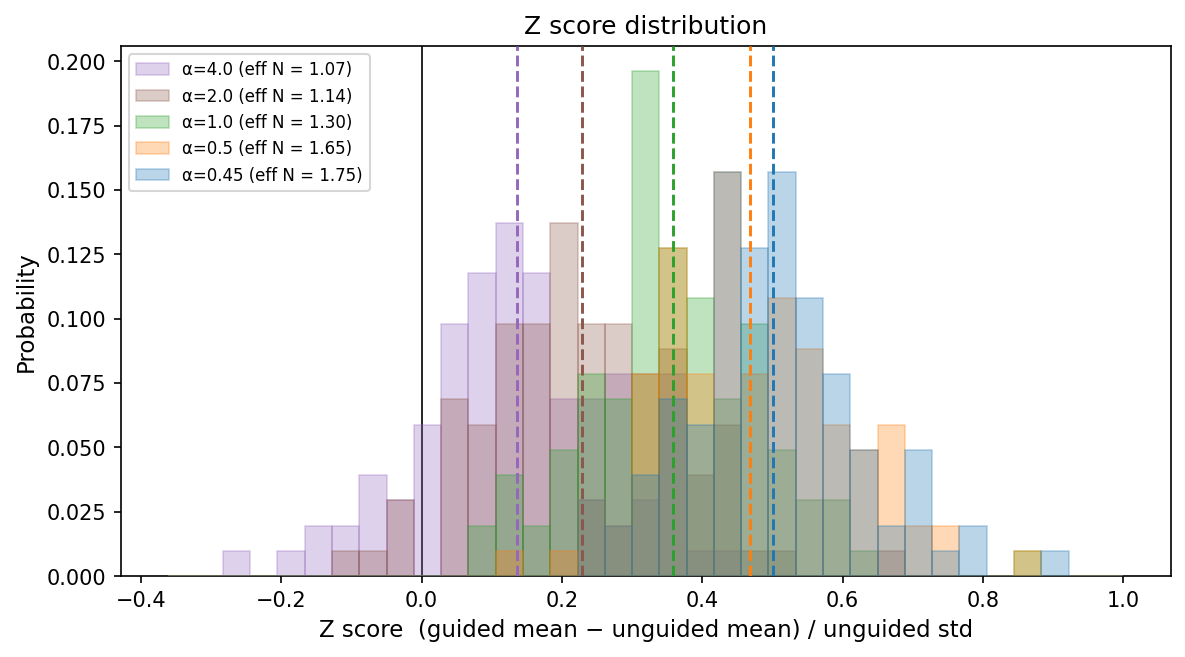

In [ ]:
# Generate figures and the results table.
REF = "lcb_clean_d0p5_a2p0.json"
!python -u "{D}/plot_survival_scaling_combined_v3.py" --results_dir "{RESULTS}" --ref "{REF}"
!python -u "{D}/plot_per_prompt_combined.py" --results_dir "{RESULTS}" --ref "{REF}"
!python -u "{D}/plot_z_score_histograms.py" --results_dir "{RESULTS}" --ref "{REF}"
!python -u "{D}/print_results_table.py" --results_dir "{RESULTS}" --ref "{REF}" --output_dir "{RESULTS}/z_score_plots"

# Display the histogram.
from IPython.display import Image, display
display(Image(filename=str(RESULTS / "z_score_plots" / "z_score_histograms.png")))
